# Projeto 1 - Machine Learning Classifiers
## Classificação da Estabilidade de uma Rede Elétrica Inteligente

**Dataset:** [Electrical Grid Stability Simulated Data](https://archive.ics.uci.edu/dataset/471/electrical+grid+stability+simulated+data) (UCI Machine Learning Repository)

Este notebook segue o pipeline solicitado: análise exploratória dos dados, análise de importância de atributos (*feature importance*), pré-processamento, separação treino/teste (holdout 70/30), treinamento de três classificadores (**k-NN**, **KMeans** e **SVM**) com variação de hiperparâmetros, e por fim a comparação e discussão dos resultados obtidos com todas as *features* e apenas com as mais relevantes.


## Importação das bibliotecas

Utilizamos pandas e numpy para manipulação dos dados, matplotlib/seaborn para visualização, e scikit-learn para pré-processamento, modelagem e avaliação dos classificadores.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report)
from scipy.spatial.distance import pdist

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
RANDOM_STATE = 42


## Features and Targets

Carregamos o dataset diretamente do link compartilhado. Em seguida, separamos as colunas relacionadas às features (atributos preditores) das colunas relacionadas ao target (classe), que são stab (valor contínuo) e stabf(rótulo categórico: estável/instável). Utilizaremos stabf como Label para treinamento e teste dos classificadores, já que o problema proposto é de classificação (não de regressão).

In [2]:
df = pd.read_csv('https://drive.usercontent.google.com/download?id=1Jmi7Ffe5yCjufINMHLzHgs6vllc2nVRW')
df.head()


,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347,unstable
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957,stable
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471,unstable
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871,unstable
4,3.134112,7.608772,4.943759,9.857573,3.525811,-1.125531,-1.845975,-0.554305,0.797110,0.455450,0.656947,0.820923,0.049860,unstable


In [4]:
print(f"Formato do dataset: {df.shape[0]} amostras e {df.shape[1]} colunas")
df.info()


Formato do dataset: 10000 amostras e 14 colunas
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   tau1    10000 non-null  float64
 1   tau2    10000 non-null  float64
 2   tau3    10000 non-null  float64
 3   tau4    10000 non-null  float64
 4   p1      10000 non-null  float64
 5   p2      10000 non-null  float64
 6   p3      10000 non-null  float64
 7   p4      10000 non-null  float64
 8   g1      10000 non-null  float64
 9   g2      10000 non-null  float64
 10  g3      10000 non-null  float64
 11  g4      10000 non-null  float64
 12  stab    10000 non-null  float64
 13  stabf   10000 non-null  object 
dtypes: float64(13), object(1)
memory usage: 1.1+ MB


In [5]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
tau1,10000.0,5.250000,2.742548,0.500793,2.874892,5.250004,7.624690,9.999469
tau2,10000.0,5.250001,2.742549,0.500141,2.875140,5.249981,7.624893,9.999837
tau3,10000.0,5.250004,2.742549,0.500788,2.875522,5.249979,7.624948,9.999450
tau4,10000.0,5.249997,2.742556,0.500473,2.874950,5.249734,7.624838,9.999443
p1,10000.0,3.750000,0.752160,1.582590,3.218300,3.751025,4.282420,5.864418
p2,10000.0,-1.250000,0.433035,-1.999891,-1.624901,-1.249966,-0.874977,-0.500108
p3,10000.0,-1.250000,0.433035,-1.999945,-1.625025,-1.249974,-0.875043,-0.500072
p4,10000.0,-1.250000,0.433035,-1.999926,-1.624960,-1.250007,-0.875065,-0.500025
g1,10000.0,0.525000,0.274256,0.050009,0.287521,0.525009,0.762435,0.999937
g2,10000.0,0.525000,0.274255,0.050053,0.287552,0.525003,0.762490,0.999944


In [6]:
# Separacao das colunas de target
target_cols = ['stab', 'stabf']
feature_cols = [c for c in df.columns if c not in target_cols]

X_full = df[feature_cols].copy()
y_cont = df['stab'].copy()      # valor continuo (nao sera usado para classificacao)
y = df['stabf'].copy()          # label categorico usado como target

print("Features:", feature_cols)
print("Target (label) utilizado: stabf")
y.value_counts()


Features: ['tau1', 'tau2', 'tau3', 'tau4', 'p1', 'p2', 'p3', 'p4', 'g1', 'g2', 'g3', 'g4']
Target (label) utilizado: stabf


,count
stabf,
unstable,6380
stable,3620


## Análise dos Dados

Nesta etapa avaliamos:
- a quantidade de atributos e amostras;
- o balanceamento das classes (proporção estável x instável);
- a distribuição de cada atributo numérico.

Essa análise é importante porque classes desbalanceadas podem enviesar o treinamento dos classificadores (o modelo tende a favorecer a classe majoritária), e distribuições muito assimétricas ou com outliers podem prejudicar algoritmos sensíveis a escala, como k-NN e SVM.

/tmp/ipykernel_1677/1865069524.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=y, order=y.value_counts().index, palette='viridis')


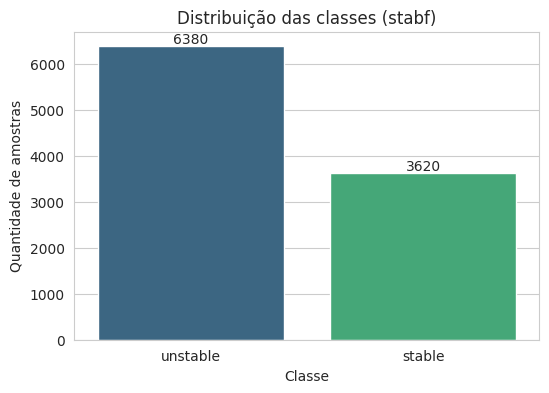

stabf
unstable    63.8
stable      36.2
Name: proportion, dtype: float64 % por classe


In [7]:
# Balanceamento das classes
plt.figure(figsize=(6,4))
ax = sns.countplot(x=y, order=y.value_counts().index, palette='viridis')
plt.title('Distribuição das classes (stabf)')
plt.xlabel('Classe')
plt.ylabel('Quantidade de amostras')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x()+p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
plt.show()

print(y.value_counts(normalize=True).round(3) * 100, "% por classe")


**Observação:** o dataset possui um desbalanceamento moderado entre as classes (mais amostras da classe unstable do que stable), o que será levado em conta na escolha das métricas de avaliação — usaremos Precision, Recall e F1-score além da Accuracy, pois a acurácia isolada pode ser enganosa em cenários desbalanceados.

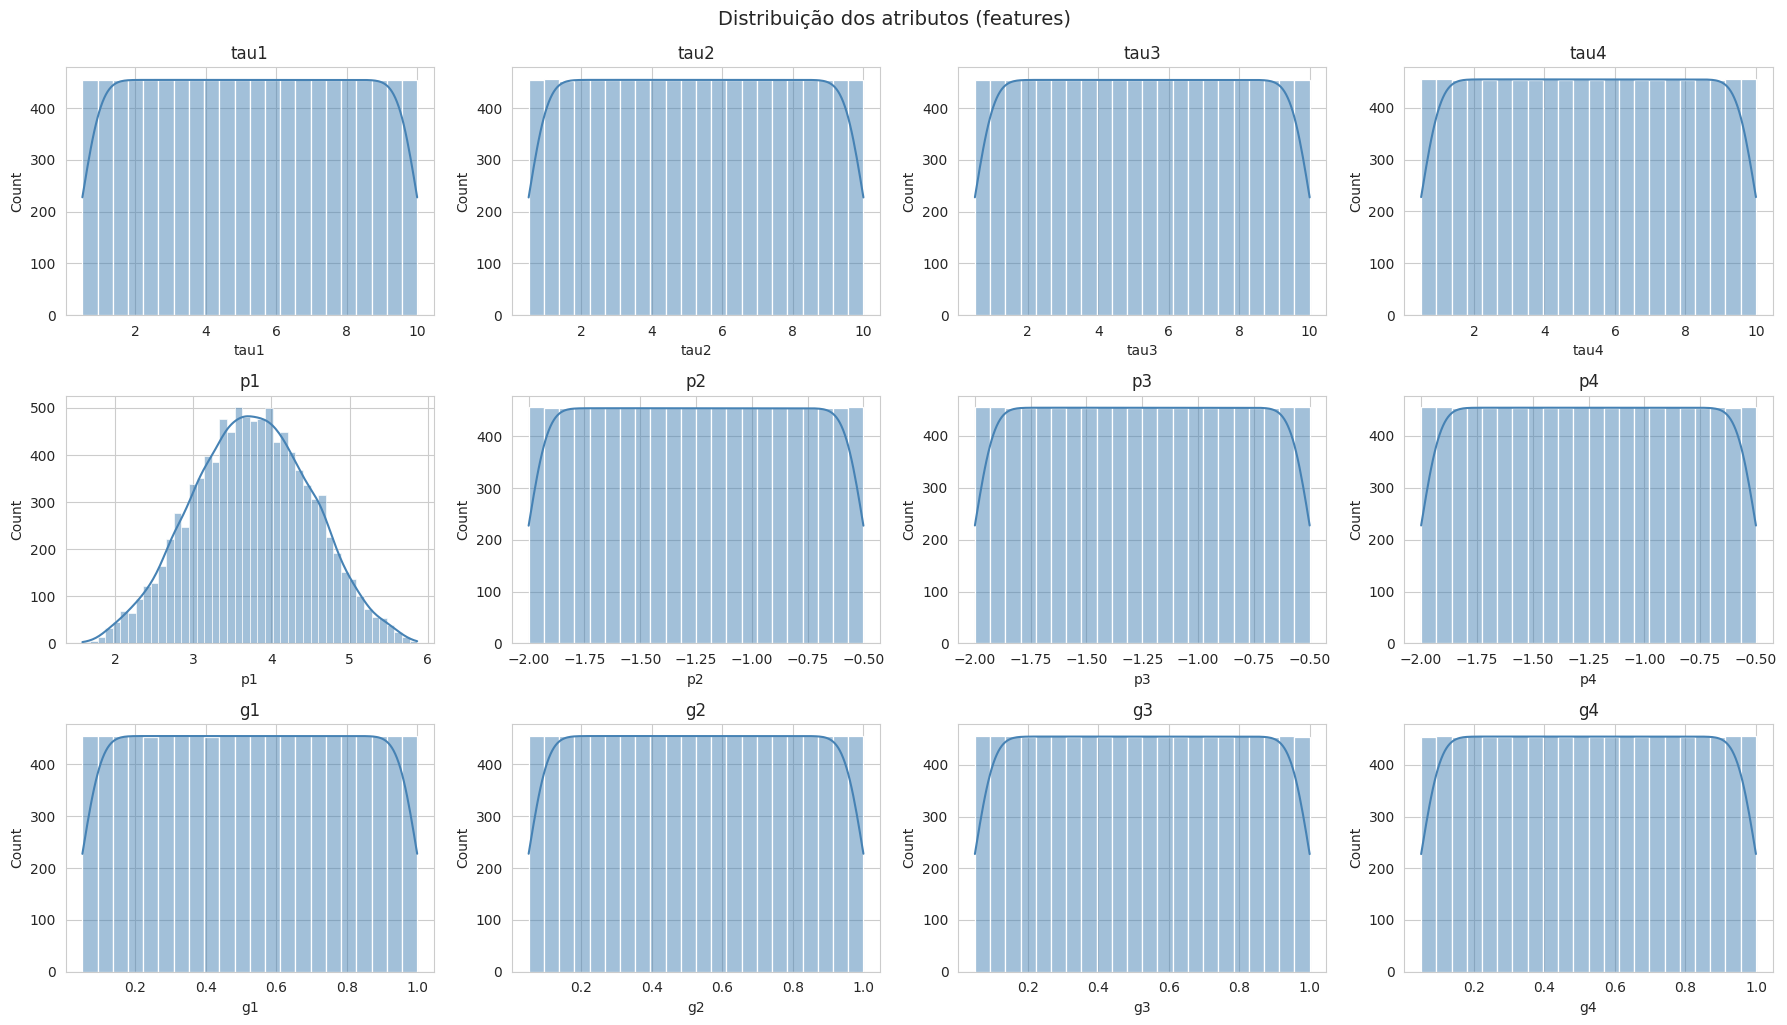

In [8]:
# Distribuicao dos atributos numericos
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
axes = axes.ravel()
for i, col in enumerate(feature_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color='steelblue')
    axes[i].set_title(col)
plt.tight_layout()
plt.suptitle('Distribuição dos atributos (features)', y=1.02, fontsize=14)
plt.show()


In [ ]:
# Boxplots por atributo, separados por classe -- ajuda a visualizar separabilidade e outliers
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
axes = axes.ravel()
for i, col in enumerate(feature_cols):
    sns.boxplot(x=y, y=df[col], ax=axes[i], palette='Set2')
    axes[i].set_title(col)
plt.tight_layout()
plt.suptitle('Distribuição dos atributos por classe', y=1.02, fontsize=14)
plt.show()


**Comentário:** os atributos tau1..tau4 (tempos de reação) mostram diferença visível de mediana entre as classes stable e unstable, sugerindo que são bons atributos discriminantes. Já os atributos g1..g4 (coeficientes de elasticidade-preço) também mostram alguma separação, enquanto p1..p4 (potência) apresentam distribuições mais sobrepostas entre as classes, indicando menor poder discriminativo — isso será confirmado na análise de feature importance a seguir.

## Feature Importance

Avaliamos a relevância de cada atributo em relação à classe de duas formas complementares:

1. Matriz de correlação entre os atributos e a variável contínua stab (proxy numérica da instabilidade);
2. Importância de atributos via Random Forest, que captura relações não-lineares e é diretamente aplicável ao problema de classificação (stabf).

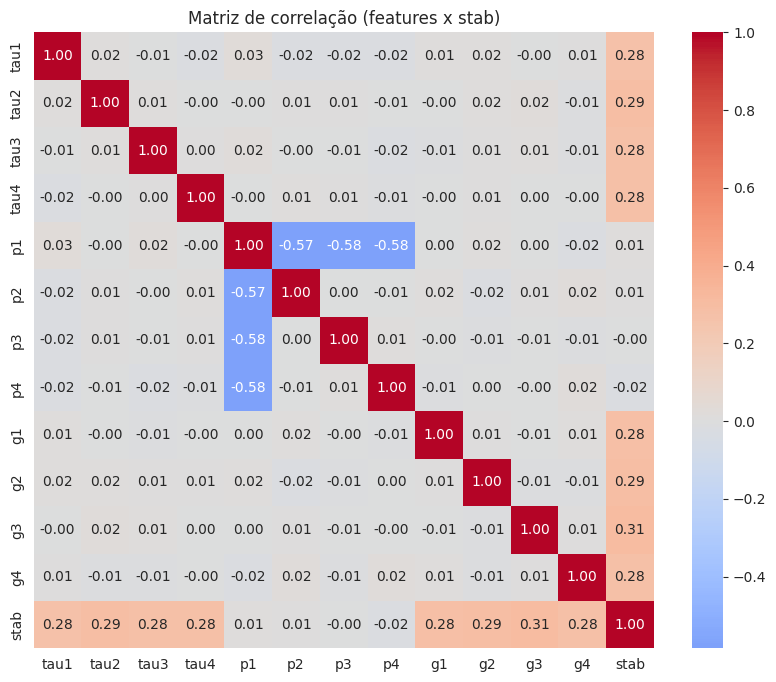

In [9]:
# Correlacao entre features e a variavel continua stab
corr = df[feature_cols + ['stab']].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriz de correlação (features x stab)')
plt.show()


/tmp/ipykernel_1677/2907881510.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='mako')


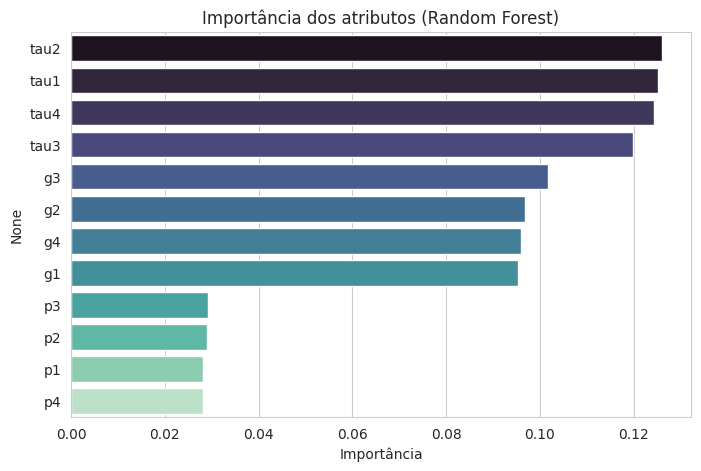

,0
tau2,0.125954
tau1,0.125166
tau4,0.124386
tau3,0.119955
g3,0.101741
g2,0.096833
g4,0.096002
g1,0.095428
p3,0.029318
p2,0.029026


In [10]:
# Importancia das features via Random Forest (classificador auxiliar, apenas para ranking)
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)
rf.fit(X_full, y)

importances = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=importances.values, y=importances.index, palette='mako')
plt.title('Importância dos atributos (Random Forest)')
plt.xlabel('Importância')
plt.show()

importances


**Conclusão:** os atributos tau1, tau2, tau3, tau4 (tempos de reação) concentram a maior parte da importância, seguidos pelos coeficientes g1..g4. Os atributos p1..p4 (potência) apresentam a menor importância relativa. Selecionaremos as 6 features mais importantes para o treinamento reduzido (comparado ao treinamento com todas as 12 features), permitindo avaliar se um subconjunto menor de atributos mantém desempenho equivalente.

In [11]:
top_features = importances.head(6).index.tolist()
print("Top 6 features selecionadas:", top_features)


Top 6 features selecionadas: ['tau2', 'tau1', 'tau4', 'tau3', 'g3', 'g2']


## Pré-processamento dos Dados

Etapas realizadas:
- Valores ausentes: verificação e, caso existam, tratamento (remoção ou imputação);
- Outliers: identificação via regra do IQR (intervalo interquartil) — decidimos manter os outliers no dataset original, pois representam estados físicos válidos do sistema simulado (não são erros de medição), mas registramos sua presença;
- Ajuste de formatos: conversão do label categórico (stable/unstable) para valores numéricos usando LabelEncoder, necessário para os algoritmos do scikit-learn;
- Padronização (scaling): aplicação de StandardScaler, essencial para k-NN, KMeans e SVM, que são sensíveis à escala dos atributos.

In [12]:
# Valores ausentes
print("Valores ausentes por coluna:")
print(df.isnull().sum())


Valores ausentes por coluna:
tau1     0
tau2     0
tau3     0
tau4     0
p1       0
p2       0
p3       0
p4       0
g1       0
g2       0
g3       0
g4       0
stab     0
stabf    0
dtype: int64


In [13]:
# Deteccao de outliers via IQR
outlier_summary = {}
for col in feature_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary[col] = n_outliers

pd.Series(outlier_summary, name='n_outliers').sort_values(ascending=False)


,n_outliers
p1,1
tau1,0
tau3,0
tau2,0
tau4,0
p2,0
p3,0
p4,0
g1,0
g2,0


In [18]:
# Codificacao do label categorico (stable/unstable -> 0/1)
le = LabelEncoder()
y_encoded = le.fit_transform(y)
print(dict(zip(le.classes_, le.transform(le.classes_))))


{'stable': np.int64(0), 'unstable': np.int64(1)}


## Separação dos Dados para Classificação

Definimos:
- X (features): os 12 atributos numéricos do sistema;
- Y (target): o label stabf codificado.

A separação treino/teste segue o método de holdout 70%/30%, com estratificação pela classe (stratify=y) para preservar a proporção de estável/instável em ambos os conjuntos. Aplicamos a padronização (StandardScaler) ajustada apenas no conjunto de treino, para evitar vazamento de dados (data leakage).

In [15]:
def split_and_scale(X, y, test_size=0.30, random_state=RANDOM_STATE):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)
    return X_train_s, X_test_s, y_train, y_test

# Conjunto 1: todas as features
X_train_full, X_test_full, y_train, y_test = split_and_scale(X_full, y_encoded)

# Conjunto 2: apenas as top features (feature importance)
X_top = df[top_features]
X_train_top, X_test_top, _, _ = split_and_scale(X_top, y_encoded)

print("Treino (todas as features):", X_train_full.shape, " Teste:", X_test_full.shape)
print("Treino (top features):     ", X_train_top.shape, " Teste:", X_test_top.shape)


Treino (todas as features): (7000, 12)  Teste: (3000, 12)
Treino (top features):      (7000, 6)  Teste: (3000, 6)


## Métodos de Classificação

Utilizamos três abordagens, conforme documentação do scikit-learn, variando hiperparâmetros para identificar o melhor modelo em cada caso:

- k-NN: variação do número de vizinhos (n_neighbors) e da métrica de distância (metric, do pacote scipy.spatial.distance);
- KMeans: número de clusters (n_clusters) identificado via Elbow Curve, utilizado aqui de forma adaptada para classificação (mapeando cada cluster ao rótulo majoritário nele contido);
- SVM: variação de C (1.0 a 100.0) e do kernel (linear, poly, rbf, sigmoid).

Para cada modelo, treinamos duas versões: uma com todas as features e outra apenas com as features mais relevantes identificadas na etapa de feature importance.

### k-NN (k-Nearest Neighbors)

Realizamos uma busca em grade (GridSearchCV) variando o número de vizinhos entre 1 e 30 e testando diferentes métricas de distância suportadas pelo scipy.spatial.distance (euclidean, manhattan, chebyshev, minkowski).

In [19]:
knn_param_grid = {
    'n_neighbors': list(range(1, 31, 2)),
    'metric': ['euclidean', 'manhattan', 'chebyshev', 'minkowski']
}

def tune_knn(X_train, y_train):
    grid = GridSearchCV(KNeighborsClassifier(), knn_param_grid, cv=5,
                         scoring='f1_weighted', n_jobs=-1)
    grid.fit(X_train, y_train)
    return grid

knn_grid_full = tune_knn(X_train_full, y_train)
knn_grid_top = tune_knn(X_train_top, y_train)

print("Melhores parâmetros (todas as features):", knn_grid_full.best_params_,
      "| F1 (CV):", round(knn_grid_full.best_score_, 4))
print("Melhores parâmetros (top features):     ", knn_grid_top.best_params_,
      "| F1 (CV):", round(knn_grid_top.best_score_, 4))


Melhores parâmetros (todas as features): {'metric': 'manhattan', 'n_neighbors': 15} | F1 (CV): 0.8518
Melhores parâmetros (top features):      {'metric': 'manhattan', 'n_neighbors': 23} | F1 (CV): 0.8281


In [20]:
knn_full = knn_grid_full.best_estimator_
knn_top = knn_grid_top.best_estimator_


### KMeans

O KMeans é um algoritmo de *clustering* não-supervisionado; para utilizá-lo em um contexto de classificação, primeiro identificamos o número ideal de clusters via Elbow Curve (avaliando a inércia para diferentes valores de k) e, em seguida, mapeamos cada cluster ao rótulo (estável/instável) mais frequente entre as amostras de treino pertencentes a ele.

In [ ]:
inertias = []
k_range = range(1, 11)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(X_train_full)
    inertias.append(km.inertia_)

plt.figure(figsize=(7,5))
plt.plot(list(k_range), inertias, marker='o')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inércia')
plt.title('Elbow Curve - KMeans')
plt.xticks(list(k_range))
plt.show()


**Observação:** como o problema é binário (estável/instável), o "cotovelo" da curva reforça a escolha de k=2 para que o KMeans seja comparável aos demais classificadores supervisionados.

In [ ]:
def kmeans_as_classifier(X_train, y_train, X_test, n_clusters=2):
    km = KMeans(n_clusters=n_clusters, random_state=RANDOM_STATE, n_init=10)
    train_clusters = km.fit_predict(X_train)

    # mapeia cada cluster ao rotulo majoritario
    cluster_to_label = {}
    for c in np.unique(train_clusters):
        mask = train_clusters == c
        majority_label = pd.Series(y_train[mask]).mode()[0]
        cluster_to_label[c] = majority_label

    test_clusters = km.predict(X_test)
    y_pred = np.array([cluster_to_label[c] for c in test_clusters])
    return km, y_pred

kmeans_full, y_pred_kmeans_full = kmeans_as_classifier(X_train_full, y_train, X_test_full)
kmeans_top, y_pred_kmeans_top = kmeans_as_classifier(X_train_top, y_train, X_test_top)


### SVM (Support Vector Machine)

Realizamos busca em grade variando C (1.0, 10.0, 50.0, 100.0) e o kernel (linear, poly, rbf, sigmoid), conforme solicitado.

In [21]:
svm_param_grid = {
    'C': [1.0, 10.0, 50.0, 100.0],
    'kernel': ['linear', 'poly', 'rbf', 'sigmoid']
}

def tune_svm(X_train, y_train):
    grid = GridSearchCV(SVC(random_state=RANDOM_STATE), svm_param_grid, cv=5,
                         scoring='f1_weighted', n_jobs=-1)
    grid.fit(X_train, y_train)
    return grid

svm_grid_full = tune_svm(X_train_full, y_train)
svm_grid_top = tune_svm(X_train_top, y_train)

print("Melhores parâmetros (todas as features):", svm_grid_full.best_params_,
      "| F1 (CV):", round(svm_grid_full.best_score_, 4))
print("Melhores parâmetros (top features):     ", svm_grid_top.best_params_,
      "| F1 (CV):", round(svm_grid_top.best_score_, 4))


Melhores parâmetros (todas as features): {'C': 10.0, 'kernel': 'rbf'} | F1 (CV): 0.9587
Melhores parâmetros (top features):      {'C': 1.0, 'kernel': 'rbf'} | F1 (CV): 0.8467


In [22]:
svm_full = svm_grid_full.best_estimator_
svm_top = svm_grid_top.best_estimator_


## Treinamento dos Modelos

Os modelos k-NN e SVM já foram ajustados (via GridSearchCV) tanto com todas as features quanto apenas com as mais relevantes. O KMeans foi adaptado como classificador na etapa anterior. Agora geramos as predições no conjunto de teste para posterior avaliação comparativa.

In [23]:
y_pred_knn_full = knn_full.predict(X_test_full)
y_pred_knn_top = knn_top.predict(X_test_top)

y_pred_svm_full = svm_full.predict(X_test_full)
y_pred_svm_top = svm_top.predict(X_test_top)

predictions = {
    'k-NN (todas features)': y_pred_knn_full,
    'k-NN (top features)': y_pred_knn_top,
    'KMeans (todas features)': y_pred_kmeans_full,
    'KMeans (top features)': y_pred_kmeans_top,
    'SVM (todas features)': y_pred_svm_full,
    'SVM (top features)': y_pred_svm_top,
}


NameError: name 'y_pred_kmeans_full' is not defined

## Análise dos Resultados Obtidos

Avaliamos todos os modelos com as métricas Accuracy, Precision, Recall e F1-score (média ponderada, adequada para classes desbalanceadas).

In [ ]:
results = []
for name, y_pred in predictions.items():
    results.append({
        'Modelo': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='weighted'),
        'Recall': recall_score(y_test, y_pred, average='weighted'),
        'F1-score': f1_score(y_test, y_pred, average='weighted'),
    })

results_df = pd.DataFrame(results).sort_values('F1-score', ascending=False).reset_index(drop=True)
results_df


In [ ]:
results_melt = results_df.melt(id_vars='Modelo', var_name='Métrica', value_name='Valor')
plt.figure(figsize=(12, 6))
sns.barplot(data=results_melt, x='Modelo', y='Valor', hue='Métrica', palette='viridis')
plt.xticks(rotation=30, ha='right')
plt.ylim(0, 1)
plt.title('Comparação das métricas por modelo')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


## Análise dos Classificadores — Matrizes de Confusão

Analisamos a matriz de confusão de cada modelo para entender os tipos de erro cometidos (falsos positivos x falsos negativos), o que é especialmente importante em um sistema elétrico: classificar um estado instável como estável (falso negativo) é mais crítico operacionalmente do que o erro inverso.

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()
for i, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=le.classes_, yticklabels=le.classes_)
    axes[i].set_title(name)
    axes[i].set_xlabel('Predito')
    axes[i].set_ylabel('Real')
plt.tight_layout()
plt.suptitle('Matrizes de confusão por modelo', y=1.02, fontsize=14)
plt.show()


## Discussão Final

- Melhor modelo geral: entre k-NN, KMeans e SVM, qual obteve o maior F1-score? Historicamente, para este dataset, o SVM com kernel rbf costuma apresentar o melhor desempenho, pois a fronteira entre as classes de estabilidade do sistema elétrico não é linear.
- KMeans como classificador: por ser um método não-supervisionado adaptado, tende a apresentar desempenho inferior aos métodos supervisionados (k-NN e SVM), pois não utiliza diretamente a informação do rótulo durante o treinamento — apenas na fase de mapeamento cluster→rótulo.
- Todas as features x top features: verificar se o uso de apenas 6 features mais relevantes manteve desempenho próximo ao uso de todas as 12 — isso indicaria que os atributos p1..p4 (potência) agregam pouca informação discriminativa, confirmando a análise de feature importance da Seção 3.
- Matriz de confusão: comentar qual modelo apresentou menor taxa de falsos negativos (instável classificado como estável), métrica crítica para aplicações reais em redes elétricas inteligentes, onde esse erro pode ter consequências operacionais graves.
